# Deck strength: predicting a draft's win rate from the cards drafted

How good is a drafted deck, and what is each card worth? This notebook explains the models that predict a
Premier Draft run's record from what the drafter took. Sections:

1. The target: an event record (W-L), and why it is modelled as a per-game win probability
2. Scoring, and the noise ceiling: how well a *perfect* model could do
3. The models and what each one sees
4. The linear deck model, fitted live: calibration, card weights, rank, a worked example
5. Deck structure (lands, curve, colours) and LightGBM
6. Game-level models: skill-adjusted card power, pair synergy, and why cards *cast* mislead
7. DraftEncoder: a transformer over the pick sequence, and how its prediction sharpens pick by pick
8. Results on MSH, and across 12 sets
9. Takeaways

Code: `src/openlane/deckstrength.py`, `src/openlane/draftencoder.py`, `src/openlane/synergy.py`, and the scripts
`train_deckstrength.py`, `train_draftencoder.py`, `improve_deck.py`, `deck_synergy.py`. Needs
`data/parquet/MSH.PremierDraft{,.game}.parquet` and the saved results under `results/*/`. The live fits run on CPU
in about a minute; the slow models (DraftEncoder, LightGBM, the synergy model) are read from their saved results.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Patch
from scipy import sparse
from scipy.stats import spearmanr

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))
from openlane.data import RANK_ORDER
from openlane.deckstrength import (N_RANKS, binomial_logreg, deck_metrics, game_split, game_win_rates,
                                   load_drafts, most_played_deck, simulate_runs, top_k_mean)
from openlane.games import game_path
from improve_deck import structure_features  # importing it does not load LightGBM

SET, EVENT = "MSH", "PremierDraft"
OUT = ROOT / "results" / f"{SET}.{EVENT}"

# reference categorical palette, fixed order (same as the other notebooks)
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"
GRAY, INK, MUTED, SURFACE, GRID = "#a3a29c", "#0b0b0b", "#52514e", "#fcfcfb", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pl.Config.set_tbl_rows(25); pl.Config.set_fmt_str_lengths(50); pl.Config.set_tbl_hide_dataframe_shape(True)

d = load_drafts(SET, EVENT)                       # one row per complete draft: final pool + record
games = pl.read_parquet(game_path(SET, EVENT))    # one row per game: registered deck, result, context
gs = game_split(d, games["draft_id"])
deck, has_deck = most_played_deck(d, games)       # each draft's most-played 40-card build
gih = game_win_rates(games.filter(pl.Series(gs == 0)), d.names)["gih_wr"]  # train games only
n_games = games.height
del games
names = np.array(d.names)
w, l = d.wins, d.losses
tr, va, te = (d.mask(s) & has_deck for s in ("train", "val", "test"))
print(f"{len(d.draft_id):,} complete drafts, {len(names)} cards, {n_games:,} games; "
      f"{has_deck.mean():.1%} of drafts have a registered deck")
print(f"split by draft time: train {tr.sum():,} / val {va.sum():,} / test {te.sum():,} (drafts with a deck)")

68,609 complete drafts, 339 cards, 377,514 games; 98.8% of drafts have a registered deck
split by draft time: train 47,552 / val 10,165 / test 10,068 (drafts with a deck)


## 1. The target: an event record

A Premier Draft run is best-of-one games until **7 wins or 3 losses**, so every finished run is 7-x or x-3. Some
runs are abandoned early (0-0, 2-1, ...). The model's output is one number per drafted deck, **p = the chance of
winning a game**.

The run's stopping rule depends only on the results so far, so it drops out of the likelihood: a run that went
W-L has likelihood p<sup>W</sup>(1-p)<sup>L</sup>, whatever order the games came in and whether the run finished.
Every model below is trained on this binomial loss. In practice that is a logistic regression in which each draft
appears twice: as a "win" row weighted W and a "loss" row weighted L. Abandoned runs count for exactly as many
games as they played. Only the 0-0 runs carry no information.

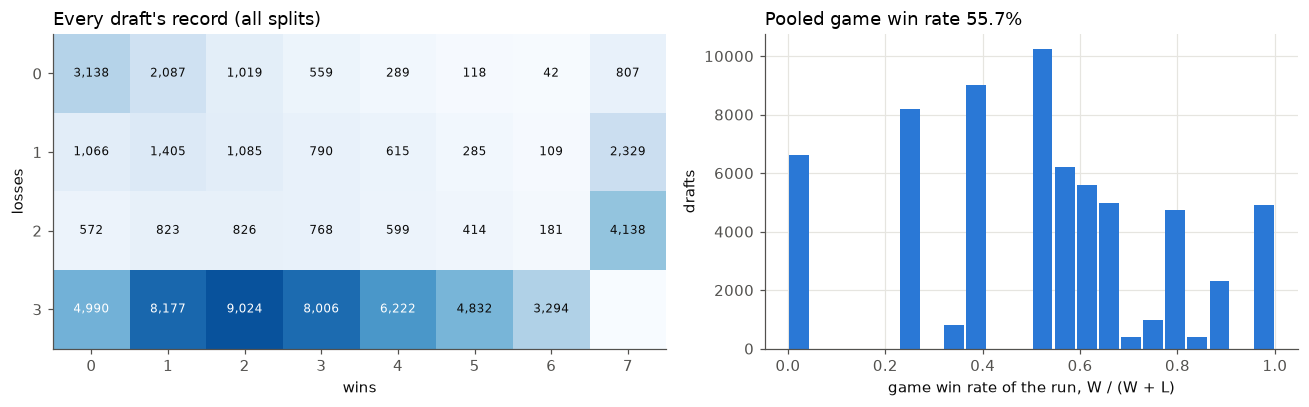

In [2]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.15, 1]})
grid = np.zeros((4, 8), dtype=int)
np.add.at(grid, (l.astype(int), w.astype(int)), 1)
im = a1.imshow(grid, cmap="Blues", aspect="auto", vmin=0, vmax=grid.max() * 1.15)
for (li, wi), n in np.ndenumerate(grid):
    if n:
        a1.text(wi, li, f"{n:,}", ha="center", va="center", fontsize=8,
                color="white" if n > grid.max() * 0.55 else INK)
a1.set_xticks(range(8)); a1.set_yticks(range(4)); a1.grid(False)
a1.set_xlabel("wins"); a1.set_ylabel("losses")
a1.set_title("Every draft's record (all splits)", loc="left")

ok = (w + l) > 0
a2.hist((w / np.maximum(w + l, 1))[ok], bins=np.linspace(0, 1, 23), color=BLUE, rwidth=0.9)
a2.set_xlabel("game win rate of the run, W / (W + L)"); a2.set_ylabel("drafts")
a2.set_title(f"Pooled game win rate {w.sum() / (w + l).sum():.1%}", loc="left")
plt.tight_layout(); plt.show()

The pooled win rate is above 50% because 17Lands users are stronger than the average Arena player they get paired
against.

## 2. Scoring, and the noise ceiling

Models are compared on held-out **test drafts**, the last 15% by draft time, with the same rows for every model.
There are two metrics:

* **Spearman** rank correlation between predicted p and the run's observed W/(W+L). This is the headline metric of
  the DraftEncoder paper (arXiv 2607.04782), which these experiments follow.
* **NLL per game**: the binomial log loss above, divided by games played. It rewards calibration as well as ranking.
  Always guessing the pooled rate scores about 0.688.

Neither number can get close to its ideal. A run is at most 9 Bo1 games, so even a deck with a true 60% win rate
often goes 2-3 or 7-1. The **ceiling** below asks how well a perfect model could score: draw each deck's true p,
play out its run under the 7-win / 3-loss rule, and compute Spearman(true p, simulated W/(W+L)). The answer depends
only on how much true deck strength varies.

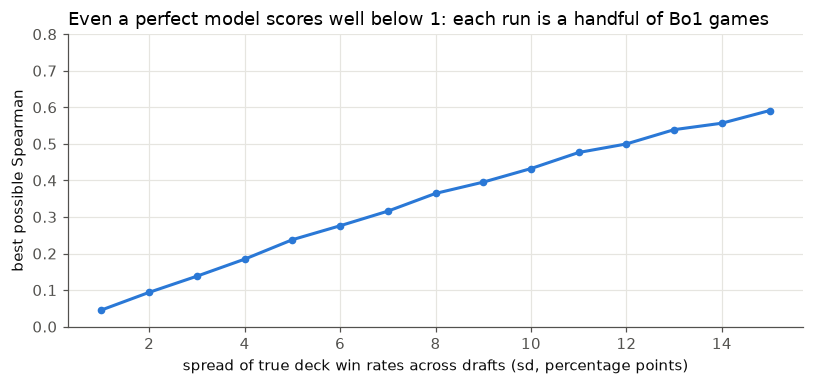

ceiling at sd = 3, 5, 8 points: [0.138, 0.238, 0.364]


In [3]:
rng = np.random.default_rng(0)
sds = np.linspace(0.01, 0.15, 15)
ceil = []
for sd in sds:
    p_true = np.clip(rng.normal(w.sum() / (w + l).sum(), sd, 40_000), 0.02, 0.98)
    ceil.append(spearmanr(p_true, simulate_runs(p_true, seed=1)).statistic)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(sds * 100, ceil, color=BLUE, marker="o", ms=4)
ax.set_xlabel("spread of true deck win rates across drafts (sd, percentage points)")
ax.set_ylabel("best possible Spearman")
ax.set_ylim(0, 0.8)
ax.set_title("Even a perfect model scores well below 1: each run is a handful of Bo1 games", loc="left")
plt.tight_layout(); plt.show()
print("ceiling at sd = 3, 5, 8 points:", [round(float(np.interp(x, sds, ceil)), 3) for x in (0.03, 0.05, 0.08)])

For each fitted model, `deck_metrics` also reports the ceiling *for that model's own predicted spread*: the score
it would get if its predictions were exactly right. When a model's test Spearman is close to its ceiling, it is
about as good as it could be at the spread it predicts. To score higher it has to find real differences between
decks that it currently misses.

## 3. The models and what each one sees

| family | input | models |
|---|---|---|
| baseline | player rank only | `rank_only` |
| heuristics | final pool or deck, scored with public card win rates | `pool_top23:gih_wr` (mean GIH WR of the best 23 cards), `deck_mean:gih_wr` |
| linear | final 42-card **pool**, as card counts | `linear_pool` |
| linear | registered 40-card **deck** (lands included), as card counts | `linear_deck`, `+structure`, `+archetype`, `+gih_prior` |
| trees | deck counts + structure features | `lgbm_deck+structure` |
| game-level | every game's deck, adjusted for play/draw, mulligans, skill and both ranks | `game_fm` (card power + pair synergy) |
| transformer | the whole **pick sequence** (every pack seen and the card taken), optionally + the deck | `draftencoder_{paper,big}[+deck]` |

The registered deck comes from 17Lands *game* data: the build the drafter actually played most. Any model that
sees the deck also benefits from the drafter's own build decisions, such as which 23 cards to play and how many
lands. The pool and pick-sequence models must work those out themselves. All models also get the player's rank;
none get the 17Lands skill bucket (the user's overall game win rate), because that is close to the answer.

## 4. The linear deck model, fitted live

`linear_deck` is a binomial logistic regression on the registered deck's card counts plus a one-hot of rank:

logit p = b + Σ<sub>cards</sub> weight<sub>c</sub> · copies<sub>c</sub> + rank<sub>r</sub>

It is simple, fits in seconds, and is within a hair of the best model on most sets. The L2 strength `C=0.01` is
the value chosen on the validation drafts in `train_draftencoder.py`.

In [4]:
ranks = np.eye(N_RANKS, dtype=np.float32)[d.rank]
dk = deck.astype(np.float32)
X_lin = sparse.hstack([sparse.csr_matrix(dk), sparse.csr_matrix(ranks)]).tocsr()
lin = binomial_logreg(X_lin[tr], w[tr], l[tr], C=0.01)
p_lin = lin.predict_proba(X_lin)[:, 1]
m_lin = deck_metrics(p_lin[te], w[te], l[te])
print(f"linear_deck on {m_lin['n']:,} test drafts: Spearman {m_lin['spearman']:.4f}, NLL {m_lin['nll']:.4f}, "
      f"own ceiling {m_lin['ceiling']:.3f}")
print(f"predicted p on test: mean {p_lin[te].mean():.3f}, sd {p_lin[te].std():.3f}, "
      f"5th-95th pct {np.percentile(p_lin[te], 5):.3f}-{np.percentile(p_lin[te], 95):.3f}")

linear_deck on 9,770 test drafts: Spearman 0.2679, NLL 0.6800, own ceiling 0.262
predicted p on test: mean 0.554, sd 0.063, 5th-95th pct 0.445-0.654


The predictions spread out with an sd of about 6 percentage points, and at that spread the noise ceiling is about
0.26. The model's actual Spearman is right at that level. So linear_deck is not wasting the spread it predicts;
**a better model has to find larger real differences between decks**, not rank the same differences more cleanly.

**Calibration.** Bin the test drafts by predicted p and compare each bin's mean prediction with the bin's pooled
win rate, ΣW / Σ(W+L). Points on the diagonal mean "p = 0.60" really does win about 60% of games.

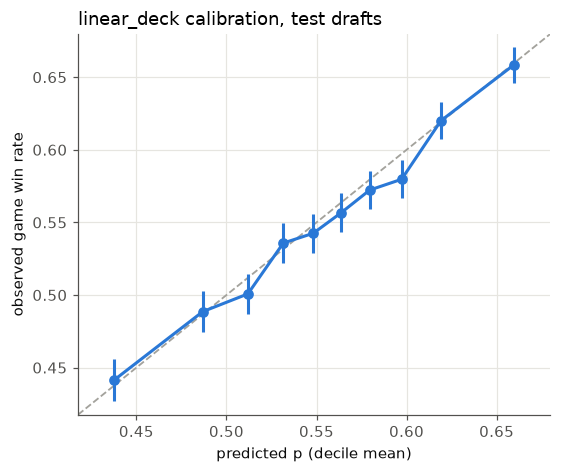

worst-decile decks win 44.1% of games, best-decile decks 65.9%


In [5]:
def calib(p, w, l, bins=10):
    edges = np.quantile(p, np.linspace(0, 1, bins + 1))
    b = np.clip(np.searchsorted(edges, p, side="right") - 1, 0, bins - 1)
    return (np.array([p[b == i].mean() for i in range(bins)]),
            np.array([w[b == i].sum() / (w[b == i] + l[b == i]).sum() for i in range(bins)]),
            np.array([(w[b == i] + l[b == i]).sum() for i in range(bins)]))

pm, obs, n = calib(p_lin[te], w[te], l[te])
fig, ax = plt.subplots(figsize=(5.2, 4.4))
lo, hi = min(pm.min(), obs.min()) - 0.02, max(pm.max(), obs.max()) + 0.02
ax.plot([lo, hi], [lo, hi], color=GRAY, lw=1.2, ls="--")
se = np.sqrt(obs * (1 - obs) / n)
ax.errorbar(pm, obs, yerr=1.96 * se, color=BLUE, marker="o", ms=6, capsize=0, lw=2)
ax.set_xlabel("predicted p (decile mean)"); ax.set_ylabel("observed game win rate")
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_title("linear_deck calibration, test drafts", loc="left")
plt.tight_layout(); plt.show()
print(f"worst-decile decks win {obs[0]:.1%} of games, best-decile decks {obs[-1]:.1%}")

**Card weights vs public win rates.** Each card's weight is the change in log-odds per copy in the deck. The
17Lands GIH WR (win rate when the card is in hand) measures much the same thing, so the two should broadly
agree. The weights are fitted jointly, so a card that is good only because it shows up in strong decks is
credited less here than in GIH WR. Only cards in at least 300 training decks are shown.

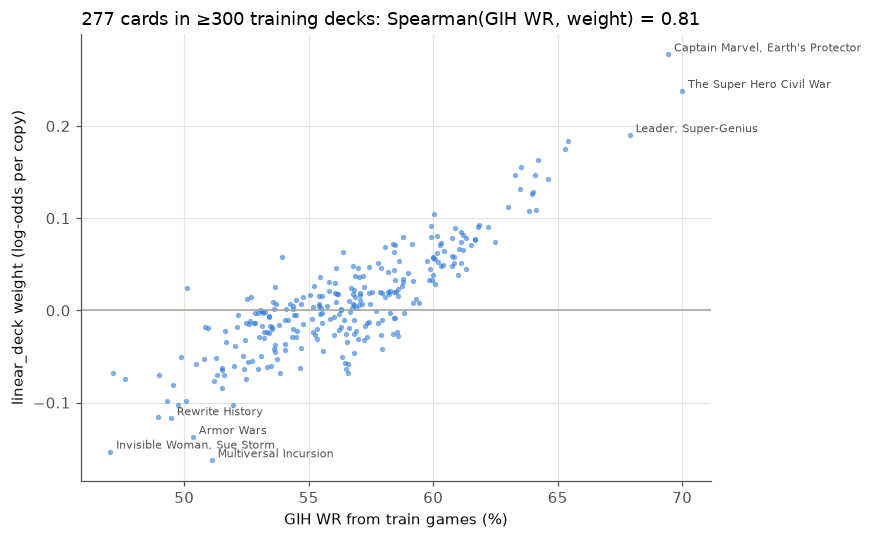

In [6]:
C = len(names)
wt = lin.coef_[0, :C]
n_decks = (deck[tr] > 0).sum(0)
cards = pl.DataFrame({"card": names, "weight": wt, "gih_wr": gih, "train_decks": n_decks})
common = cards.filter(pl.col("train_decks") >= 300)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(common["gih_wr"] * 100, common["weight"], s=12, color=BLUE, alpha=0.6, lw=0)
r = spearmanr(common["gih_wr"], common["weight"]).statistic
lab = pl.concat([common.sort("weight").head(4), common.sort("weight").tail(3)])
for row in lab.iter_rows(named=True):
    ax.annotate(row["card"], (row["gih_wr"] * 100, row["weight"]), fontsize=7.5, color=MUTED,
                xytext=(4, 2), textcoords="offset points")
ax.axhline(0, color=GRAY, lw=1)
ax.set_xlabel("GIH WR from train games (%)"); ax.set_ylabel("linear_deck weight (log-odds per copy)")
ax.set_title(f"{common.height} cards in ≥300 training decks: Spearman(GIH WR, weight) = {r:.2f}", loc="left")
plt.tight_layout(); plt.show()

In [7]:
show = lambda df: df.with_columns(pl.col("weight").round(3), (pl.col("gih_wr") * 100).round(1))
print("Highest weights"); display(show(common.sort("weight", descending=True).head(10)))
print("Lowest weights"); display(show(common.sort("weight").head(10)))

Highest weights


card,weight,gih_wr,train_decks
str,f32,f64,i64
"""Captain Marvel, Earth's Protector""",0.278,69.4,1340
"""The Super Hero Civil War""",0.238,70.0,2910
"""Leader, Super-Genius""",0.19,67.9,3043
"""Jennifer Walters""",0.184,65.4,1288
"""Doctor Doom""",0.175,65.3,1181
"""Avengers: Under Siege""",0.163,64.2,1892
"""M.O.D.O.K.""",0.156,63.5,1140
"""Elektra, Daughter of the Hand""",0.147,63.3,2217
"""Wolverine, Fierce Fighter""",0.146,64.1,1999


Lowest weights


card,weight,gih_wr,train_decks
str,f32,f64,i64
"""Multiversal Incursion""",-0.163,51.1,763
"""Invisible Woman, Sue Storm""",-0.153,47.0,1144
"""Armor Wars""",-0.137,50.3,595
"""Rewrite History""",-0.117,49.5,920
"""Hex Magic""",-0.116,48.9,341
"""Super Strength""",-0.103,51.9,572
"""Madame Hydra""",-0.103,49.7,2290
"""Construct a Cosmic Cube""",-0.099,50.1,1038
"""Super Speed""",-0.098,49.3,552


**Rank.** Arena pairs players within their rank, so rank decides *who you play*. With the deck held fixed,
the same 40 cards win less often at Diamond or Mythic than at Bronze, because the opponents are better. Rank is
not a proxy for the drafter's skill here; that would push the other way. Shown relative to Bronze.

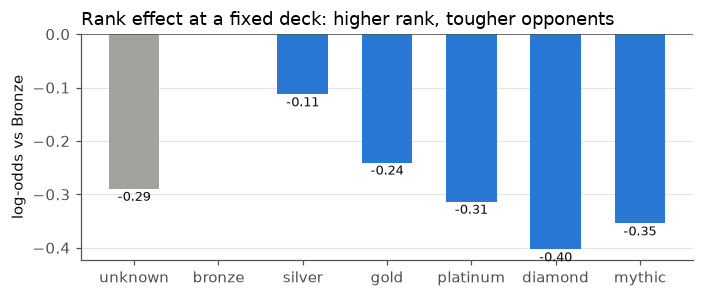

In [8]:
rk = lin.coef_[0, C:]
labels = ["unknown"] + list(RANK_ORDER)
base = rk[1]
pmean = w[tr].sum() / (w[tr] + l[tr]).sum()
fig, ax = plt.subplots(figsize=(6.5, 2.8))
vals = rk - base
ax.bar(labels, vals, color=[GRAY] + [BLUE] * 6, width=0.6)
for i, v in enumerate(vals):
    if i == 1: continue
    ax.text(i, v + (0.004 if v >= 0 else -0.004), f"{v:+.2f}", ha="center",
            va="bottom" if v >= 0 else "top", fontsize=8.5, color=INK)
ax.axhline(0, color=MUTED, lw=1)
ax.set_ylabel("log-odds vs Bronze"); ax.grid(axis="x", visible=False)
ax.set_title("Rank effect at a fixed deck: higher rank, tougher opponents", loc="left")
plt.tight_layout(); plt.show()

**A worked example.** The highest- and lowest-rated test decks, with each card's contribution to the logit
(weight × copies). Basic lands have weights too: once the deck size is fixed, a basic land's weight says how
playing it compares with playing a spell.

In [9]:
def explain(i, k=8):
    row = deck[i]
    idx = np.flatnonzero(row)
    contrib = wt[idx] * row[idx]
    df = (pl.DataFrame({"card": names[idx], "copies": row[idx].astype(int), "contribution": contrib})
          .sort("contribution", descending=True).with_columns(pl.col("contribution").round(3)))
    print(f"predicted p = {p_lin[i]:.3f}; actual record {int(w[i])}-{int(l[i])}; rank {labels[d.rank[i]]}; "
          f"card total {contrib.sum():+.2f} log-odds over {int(row.sum())} cards")
    display(pl.concat([df.head(k), df.tail(4)]))

te_idx = np.flatnonzero(te)
explain(te_idx[np.argmax(p_lin[te])])
explain(te_idx[np.argmin(p_lin[te])])

predicted p = 0.760; actual record 6-3; rank bronze; card total +0.77 log-odds over 40 cards


card,copies,contribution
str,i64,f32
"""The Super Hero Civil War""",1,0.238
"""Jennifer Walters""",1,0.184
"""Wolverine, Fierce Fighter""",1,0.146
"""Vision Quest""",1,0.09
"""Hero in Training""",1,0.078
"""Kang the Conqueror""",1,0.078
"""Web Up""",1,0.064
"""Spider-Woman, Secret Agent""",1,0.052
"""Stark Industries""",1,-0.034


predicted p = 0.305; actual record 0-3; rank diamond; card total -0.80 log-odds over 40 cards


card,copies,contribution
str,i64,f32
"""Klaw, Sonic Subjugator""",2,0.074
"""Killmonger, Scourge of Wakanda""",1,0.074
"""Super-Adaptoid""",1,0.069
"""Hour of Defeat""",1,0.025
"""Whiplash, Vengeful Engineer""",1,0.019
"""Ninja of the Hand""",1,0.007
"""The Masters of Evil""",1,0.002
"""Hell's Kitchen""",1,-0.01
"""A.I.M. Synthoids""",2,-0.084


## 5. Deck structure, and LightGBM

A sum of per-card weights cannot see *how the deck is built*: 15 lands vs 18, a top-heavy curve, a three-colour
mana base. `structure_features` (in `improve_deck.py`) adds:

* land count, one-hot from 14 to 19+
* the nonland curve: card counts at mana values 0-1, 2, 3, 4, 5, 6+
* creature count
* number of main colours (≥4 nonland cards of that colour), and number of splashed colours

Below, `+structure` is refitted live and its structure coefficients are plotted. Land and colour counts are
one-hot, so read those relative to each other. Curve and creature terms are per 5 and per 10 cards.

+structure: Spearman 0.2796 (linear_deck 0.2679), NLL 0.6792 (linear_deck 0.6800)


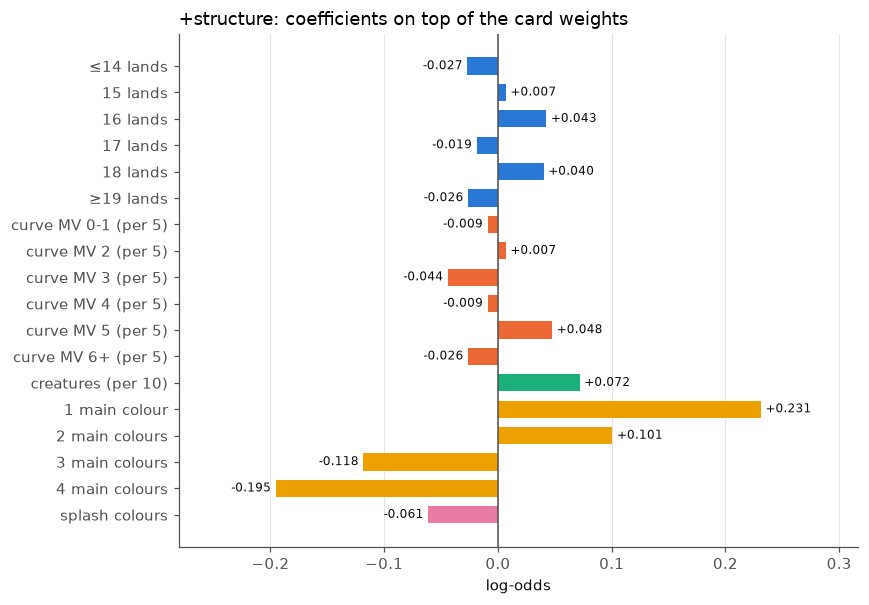

share of decks by land count: {'≤14': '0.1%', '15': '1.0%', '16': '22.4%', '17': '75.7%', '18': '0.7%', '≥19': '0.1%'}


In [10]:
st = structure_features(deck, d.names, SET)
st_names = ([f"{n} lands" for n in ("≤14", "15", "16", "17", "18", "≥19")]
            + [f"curve MV {m} (per 5)" for m in ("0-1", "2", "3", "4", "5", "6+")]
            + ["creatures (per 10)"] + [f"{n} main colour{'s' if n > 1 else ''}" for n in (1, 2, 3, 4)]
            + ["splash colours"])
X_st = sparse.hstack([X_lin, sparse.csr_matrix(st)]).tocsr()
lst = binomial_logreg(X_st[tr], w[tr], l[tr], C=0.01)
p_st = lst.predict_proba(X_st)[:, 1]
m_st = deck_metrics(p_st[te], w[te], l[te])
print(f"+structure: Spearman {m_st['spearman']:.4f} (linear_deck {m_lin['spearman']:.4f}), "
      f"NLL {m_st['nll']:.4f} (linear_deck {m_lin['nll']:.4f})")

coef = lst.coef_[0, -st.shape[1]:]
groups = [(0, 6, BLUE), (6, 12, ORANGE), (12, 13, AQUA), (13, 17, YELLOW), (17, 18, MAGENTA)]
fig, ax = plt.subplots(figsize=(8, 5.6))
y = np.arange(len(coef))[::-1]
for a, b, c in groups:
    ax.barh(y[a:b], coef[a:b], color=c, height=0.65)
for yi, v in zip(y, coef):
    ax.text(v + (0.004 if v >= 0 else -0.004), yi, f"{v:+.3f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=8, color=INK)
ax.set_yticks(y, st_names); ax.axvline(0, color=MUTED, lw=1); ax.grid(axis="y", visible=False)
ax.set_xlabel("log-odds"); ax.margins(x=0.2)
ax.set_title("+structure: coefficients on top of the card weights", loc="left")
plt.tight_layout(); plt.show()
lands, cnt = np.unique(st[has_deck, :6].argmax(1), return_counts=True)
print("share of decks by land count:", {st_names[i].split()[0]: f"{c / cnt.sum():.1%}" for i, c in zip(lands, cnt)})

How to read this:

* **Colours matter most.** Holding the cards fixed, each extra main colour costs about 0.1-0.15 log-odds, and each
  splashed colour costs another 0.06. That is the price of an inconsistent mana base, which a per-card sum cannot see.
* **More creatures help** (+0.07 per 10).
* **Land count and curve terms are small and noisy.** About 76% of decks play 17 lands and 22% play 16, so the
  other land counts have little data. The 16 vs 17 difference (+0.06 for 16) suggests 16-land decks were slightly
  better than their cards alone predict on MSH. That could be a real effect, or it could be that the players who
  cut a land are better players.

Together, these features add about +0.012 Spearman on MSH and +0.015 on average across sets.

**LightGBM** (`lgbm_deck+structure`) gets the same inputs (deck counts, structure, rank) and can learn
interactions, such as "this card is only good with enough creatures". It uses the same two-rows-per-draft binomial
trick, with early stopping on validation drafts. It is not refitted here: LightGBM and PyTorch each bundle their
own OpenMP runtime, and loading both in one process crashes on macOS (see the comment in `improve_deck.py`). The
saved results:

In [11]:
imp = json.loads((OUT / "draftencoder" / "improve_deck.json").read_text())
abl = json.loads((OUT / "draftencoder" / "lgbm_ablation.json").read_text())
tab = lambda rows: pl.DataFrame([{"model": k, "Spearman": round(v["spearman"], 4), "NLL/game": round(v["nll"], 5),
                                  "own ceiling": round(v["ceiling"], 3)} for k, v in rows.items()])
print(f"improve_deck.py, {SET} test drafts with a deck"); display(tab(imp))
print("LightGBM ablation: which inputs matter"); display(tab(abl))

improve_deck.py, MSH test drafts with a deck


model,Spearman,NLL/game,own ceiling
str,f64,f64,f64
"""linear_deck""",0.2679,0.67998,0.262
"""+structure""",0.2796,0.67917,0.268
"""+gih_prior""",0.2684,0.67996,0.26
"""+structure+gih_prior""",0.2801,0.67914,0.273
"""+structure+archetype""",0.2799,0.6792,0.27
"""lgbm_deck+structure""",0.2794,0.67935,0.284
"""game_fm""",0.2508,0.68125,0.279
"""ens linear_deck+game_fm""",0.268,0.68007,0.261
"""ens +structure+archetype+game_fm""",0.275,0.67965,0.265


LightGBM ablation: which inputs matter


model,Spearman,NLL/game,own ceiling
str,f64,f64,f64
"""deck+rank""",0.28,0.67936,0.273
"""deck+structure+rank""",0.2794,0.67935,0.284
"""presence+structure+rank""",0.2757,0.67936,0.281
"""structure+rank only""",0.0909,0.68661,0.108


LightGBM and `+structure` tie on MSH. Averaged across sets, LightGBM is ahead by about +0.013 (section 8). The
ablation shows where its signal comes from: **structure alone is weak** (0.09), and deck counts plus rank already
reach 0.28. Counts beat presence: a second copy of a good card adds value. The best MSH number, 0.285, is a logit
average of `+structure` and LightGBM. The two make different enough errors that averaging helps a little.

## 6. Game-level models: card power, pair synergy, and cards cast

The draft-level models above learn from about 40k records. 17Lands game data has one row per **game**, about 8×
as many examples. Each game also records context the record does not: play/draw, both players' mulligans, the
user's skill bucket, and both players' ranks. `deck_synergy.py` fits

P(win game) = σ(b + f(deck) + covariates),   f(x) = w·x + Σ<sub>i<j</sub> x<sub>i</sub>x<sub>j</sub>⟨v<sub>i</sub>, v<sub>j</sub>⟩

The covariates absorb skill, so w is *skill-adjusted card power*. The second term is a factorization machine:
each card gets a small vector v, and a pair's synergy is the dot product of their vectors (rank 4 or 16). f is then
used as a deck score for the test records like any other model (`game_fm`).

In [12]:
syn = json.loads((OUT / "deck_synergy" / "results.json").read_text())
display(pl.DataFrame([{"model": k, "game log loss": round(v["test_logloss"], 4), "game AUC": round(v["test_auc"], 4),
                       "draft Spearman": round(v["draft_spearman"], 4) if "draft_spearman" in v else None}
                      for k, v in syn.items()]))
power = pl.read_csv(OUT / "deck_synergy" / "card_power.csv")
pairs = pl.read_csv(OUT / "deck_synergy" / "pair_synergy.csv")
print(f"sd of linear card power: {power['power_linear'].std():.3f} log-odds; "
      f"sd of pair synergy (pairs in ≥2000 training games): {pairs['synergy'].std():.4f}")
print("Strongest positive pairs"); display(pairs.sort("synergy", descending=True).head(8)
                                           .with_columns(pl.col("synergy").round(4)))
print("Strongest negative pairs"); display(pairs.sort("synergy").head(8).with_columns(pl.col("synergy").round(4)))

model,game log loss,game AUC,draft Spearman
str,f64,f64,f64
"""cov_only""",0.6613,0.624,null
"""linear""",0.6572,0.6345,0.2506
"""fm4""",0.6578,0.6331,0.2508
"""fm16""",0.6591,0.6308,0.2554


sd of linear card power: 0.057 log-odds; sd of pair synergy (pairs in ≥2000 training games): 0.0012
Strongest positive pairs


card_a,card_b,synergy,games_together
str,str,f64,i64
"""HYDRA Assault Robot""","""Hydraulic Helper""",0.0075,5770
"""Madame Hydra""","""Yellowjacket, Heartless Marauder""",0.0073,3543
"""HYDRA Assault Robot""","""Yellowjacket, Heartless Marauder""",0.0062,2762
"""Birnin Zana Plaza""","""Wakandan Royal Guard""",0.0062,8111
"""HYDRA Assault Robot""","""Machinesmith Automaton""",0.0062,8142
"""Hydraulic Helper""","""Machinesmith Automaton""",0.006,5935
"""Birnin Zana Plaza""","""Patriot, Shield Wielder""",0.0059,5430
"""Baron Strucker, HYDRA Overlord""","""Yellowjacket, Heartless Marauder""",0.0057,5714


Strongest negative pairs


card_a,card_b,synergy,games_together
str,str,f64,i64
"""Birnin Zana Plaza""","""Pym Technologies""",-0.0053,5654
"""Birnin Zana Plaza""","""Stature, Size Shifter""",-0.0053,2164
"""A.I.M. Scientists""","""Shuri, Wakandan Inventor""",-0.0051,4233
"""Ant-Man's Army""","""S.H.I.E.L.D. Spy Kit""",-0.005,4815
"""Rapid Rescue""","""S.H.I.E.L.D. Spy Kit""",-0.005,2164
"""Baxter Building""","""S.H.I.E.L.D. Spy Kit""",-0.005,7109
"""Bold Biochemist""","""Hydraulic Helper""",-0.0049,7411
"""S.H.I.E.L.D. Spy Kit""","""Undercover Skrull""",-0.0048,6187


Two results:

* **Pair synergy is almost undetectable.** Pair terms have an sd of about 0.001 log-odds, against 0.06 for single
  cards, and the FMs do not beat the linear model on held-out games. The top pairs make thematic sense (the HYDRA /
  artifact package, the Wakandan / Birnin Zana pair), but they are tiny effects. At this data size, a deck's
  strength is close to the sum of its cards.
* **More data per example did not help.** Fitted per game with skill controls, the card power scores 0.251 as a
  deck score, *below* the draft-level `linear_deck` (0.268). Controlling for the skill bucket also removes signal
  the record target can use: good players build better decks *and* win more with them. The draft-level model is
  allowed to credit the deck for both.

**Cards cast are a trap.** Replay data records every spell each player cast, turn by turn. A Bradley-Terry fit on
(user casts − opponent casts) predicts single games extremely well, as the AUC climbs with the turn cutoff below.
Most of that is reverse causation, though: the player who is winning gets to cast more spells. Turned back into a
card value and used to score decks, it is *worse* than plain GIH WR (`train_deckstrength.py`):

In [13]:
ds = json.loads((OUT / "deckstrength" / "results.json").read_text())
display(pl.DataFrame([{"game model": k, "game AUC": round(v["auc"], 4)} for k, v in ds["game"].items()]))
keys = ["pool_top23:gih_wr", "pool_top23:cast_bt_t3", "pool_top23:cast_bt_t8", "pool_top23:cast_bt_t30",
        "pool_top23:gp_wr"]
display(pl.DataFrame([{"deck score (top-23 of the pool)": k.split(":")[1], "draft Spearman": round(ds["deck"][k]["spearman"], 4)}
                      for k in keys]))

game model,game AUC
str,f64
"""covariates_only""",0.624
"""cast_bt_t3""",0.6838
"""cast_bt_t5""",0.7347
"""cast_bt_t8""",0.7917
"""cast_bt_t30""",0.8408
"""cast_bt_t30_asym""",0.8413


deck score (top-23 of the pool),draft Spearman
str,f64
"""gih_wr""",0.213
"""cast_bt_t3""",0.1199
"""cast_bt_t8""",0.1424
"""cast_bt_t30""",0.1351
"""gp_wr""",0.1655


## 7. DraftEncoder: reading the whole draft

DraftEncoder (arXiv 2607.04782) predicts the run's record from the **pick sequence**: all 42 packs the drafter saw
and the card taken from each. It outputs a prediction after *every* pick. The paper builds card features from
oracle text; this reimplementation (`src/openlane/draftencoder.py`) has no oracle text, so a card is a learned
embedding plus metadata (public win rates, colours, mana value, creature, rarity).

* **Set context.** Every card in the set is a token. A FiLM layer conditions them on player rank, then
  self-attention runs over the whole set, giving card embeddings in the context of this set and rank.
* **Draft layers** (5 in `paper`, 8 in `big`). At each pick t there are tokens for the pack's cards and one
  *state* token s[t], initialised with the picked card. In each layer, the pack cards attend causally (with RoPE)
  over the states s[0..t]: what has the drafter committed to? Then s[t] attends over its pack, with the picked
  card as the query: what did they take, given what else was there?
* **Head.** p(win) from [s[t], rank] after each pick. The binomial loss is weighted (t+1)/42, so later picks count more.
* **Deck stage** (`+deck`, not in the paper). The registered deck as (card, copies) tokens plus the final state,
  two or three self-attention layers, and a second head.

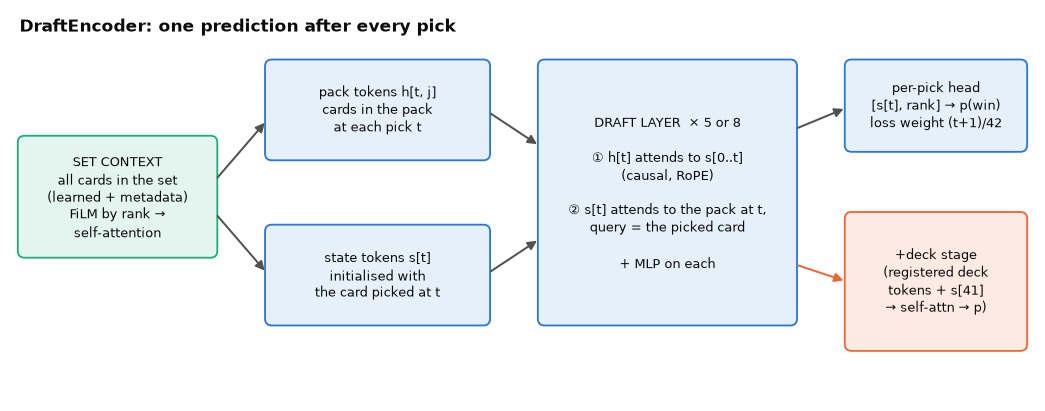

In [14]:
def box(ax, x, y, w_, h, text, fc, ec, fs=8.5):
    ax.add_patch(FancyBboxPatch((x, y), w_, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec=ec, lw=1.2))
    ax.text(x + w_ / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, color=INK, linespacing=1.35)

def arrow(ax, a, b, color=MUTED):
    ax.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", mutation_scale=12, color=color, lw=1.3, shrinkA=2, shrinkB=2))

SET_FC, DRAFT_FC, DECK_FC = "#e3f5ee", "#e6f0fb", "#fdebe3"
fig, ax = plt.subplots(figsize=(12, 4.6))
ax.set_xlim(0, 12); ax.set_ylim(0, 4.6); ax.axis("off"); ax.grid(False)
box(ax, 0.1, 1.7, 2.3, 1.4, "SET CONTEXT\nall cards in the set\n(learned + metadata)\nFiLM by rank →\nself-attention", SET_FC, AQUA)
box(ax, 3.0, 2.85, 2.6, 1.15, "pack tokens h[t, j]\ncards in the pack\nat each pick t", DRAFT_FC, BLUE)
box(ax, 3.0, 0.9, 2.6, 1.15, "state tokens s[t]\ninitialised with\nthe card picked at t", DRAFT_FC, BLUE)
arrow(ax, (2.4, 2.6), (3.0, 3.3)); arrow(ax, (2.4, 2.2), (3.0, 1.5))
box(ax, 6.2, 0.9, 3.0, 3.1, "DRAFT LAYER  × 5 or 8\n\n① h[t] attends to s[0..t]\n(causal, RoPE)\n\n② s[t] attends to the pack at t,\nquery = the picked card\n\n+ MLP on each", DRAFT_FC, BLUE)
arrow(ax, (5.6, 3.4), (6.2, 3.0)); arrow(ax, (5.6, 1.5), (6.2, 1.9))
box(ax, 9.8, 2.95, 2.1, 1.05, "per-pick head\n[s[t], rank] → p(win)\nloss weight (t+1)/42", DRAFT_FC, BLUE)
box(ax, 9.8, 0.6, 2.1, 1.6, "+deck stage\n(registered deck\ntokens + s[41]\n→ self-attn → p)", DECK_FC, ORANGE)
arrow(ax, (9.2, 3.2), (9.8, 3.45)); arrow(ax, (9.2, 1.6), (9.8, 1.4), color=ORANGE)
ax.text(0.1, 4.35, "DraftEncoder: one prediction after every pick", fontsize=11, color=INK, fontweight="bold")
plt.show()

Because the model predicts after every pick, it shows how much the draft so far reveals about the final record.
The dashed lines are the linear models, which only see the end result.

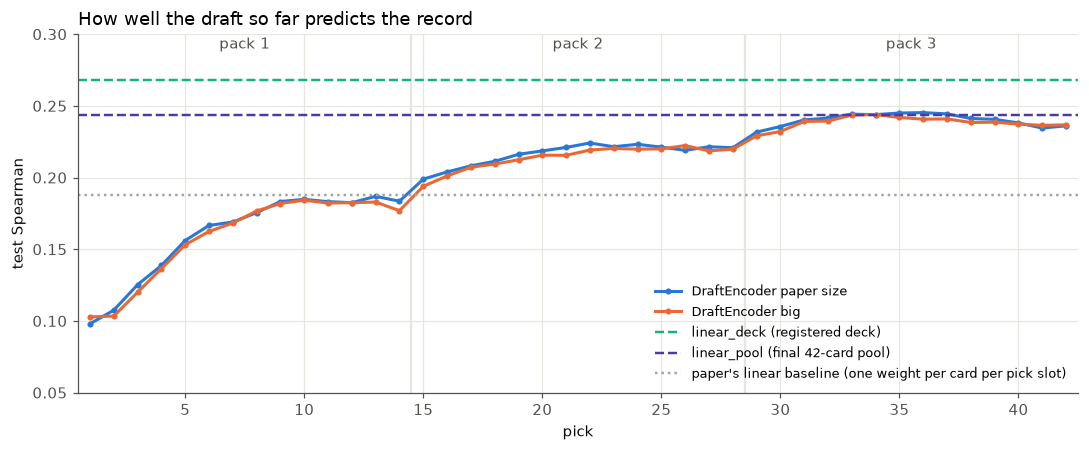

pick 1: 0.1028  pick 14: 0.1769  best: 0.2439  pick 42: 0.2368


In [15]:
de = json.loads((OUT / "draftencoder" / "results.json").read_text())
fig, ax = plt.subplots(figsize=(10, 4.2))
picks = np.arange(1, 43)
for k, c, lab in (("draftencoder_paper", BLUE, "DraftEncoder paper size"),
                  ("draftencoder_big", ORANGE, "DraftEncoder big")):
    ax.plot(picks, de[k]["spearman_by_pick"], color=c, label=lab, marker="o", ms=3)
for k, c, lab in (("linear_deck", AQUA, "linear_deck (registered deck)"),
                  ("linear_pool", VIOLET, "linear_pool (final 42-card pool)")):
    ax.axhline(de[k]["spearman"], color=c, ls="--", lw=1.6, label=lab)
pb = json.loads((OUT / "draftencoder" / "paper_baselines.json").read_text())["paper_lr_order_dependent"]
ax.axhline(pb["spearman"], color=GRAY, ls=":", lw=1.6, label="paper's linear baseline (one weight per card per pick slot)")
for x in (14.5, 28.5):
    ax.axvline(x, color=GRID, lw=1.5, zorder=0)
for x, t in ((7.5, "pack 1"), (21.5, "pack 2"), (35.5, "pack 3")):
    ax.text(x, 0.29, t, ha="center", color=MUTED)
ax.set_xlabel("pick"); ax.set_ylabel("test Spearman"); ax.set_xlim(0.5, 42.5); ax.set_ylim(0.05, 0.3)
ax.legend(loc="lower right", fontsize=8.5)
ax.set_title("How well the draft so far predicts the record", loc="left")
plt.tight_layout(); plt.show()
print("pick 1:", de["draftencoder_big"]["spearman_by_pick"][0], " pick 14:", de["draftencoder_big"]["spearman_by_pick"][13],
      " best:", max(de["draftencoder_big"]["spearman_by_pick"]), " pick 42:", de["draftencoder_big"]["spearman_by_pick"][-1])

What the curve shows:

* **Pick 1 already carries signal** (0.10). The first pick, plus rank, says something about the drafter, probably
  because strong players take strong cards.
* **Pack 1 levels off by about pick 9.** Later picks in a pack are leftovers and say little. Each new pack brings
  a jump, as the drafter's colours firm up and the strong picks show up.
* **With no deck, it never beats the bag-of-cards `linear_pool`** (0.243). It catches up around pick 33 and then
  drifts down slightly. Pick order and the passed cards add nothing that a linear model on the final pool
  doesn't already capture. Without oracle text, the transformer's card representations are no better than
  per-card weights.
* **The paper's own linear baseline is weak** (0.188, dotted). It gives each card a separate weight for every pick
  slot, which spreads the data 42 ways. Beating it says little; the plain bag-of-cards model is the bar to clear.
* **`+deck` closes most of the gap** (0.266 for big), but it still lands slightly *below* `linear_deck` alone (0.268).

## 8. Results

### MSH: every model on the same test drafts

All rows are scored on the same MSH test drafts with a registered deck. Colour shows what the model reads.

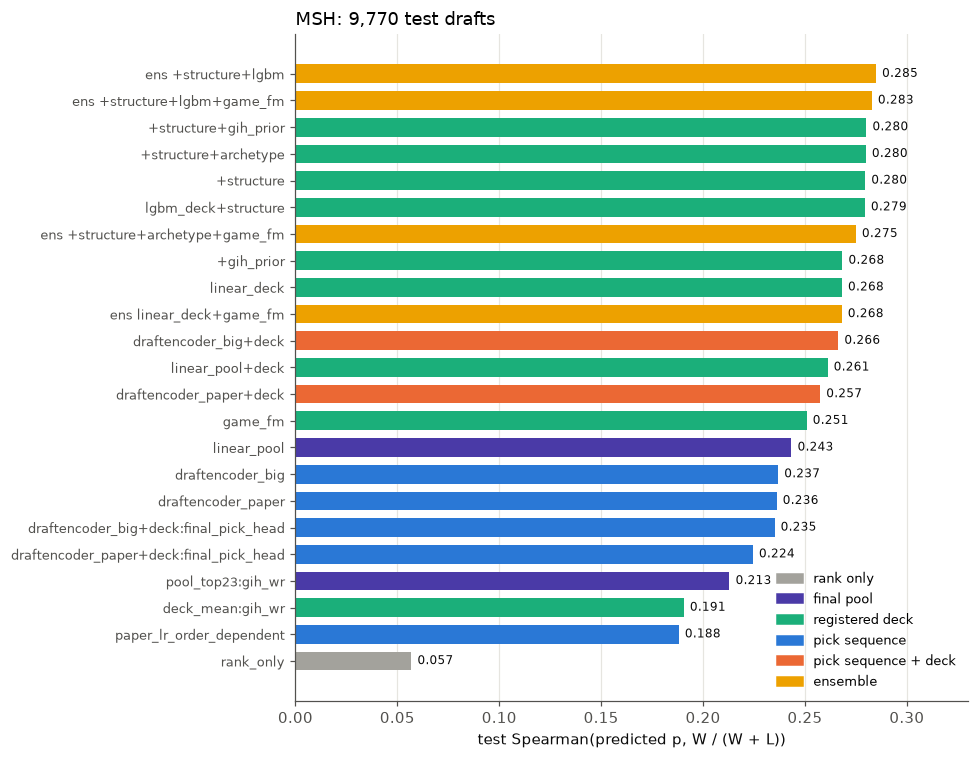

model,reads,Spearman,NLL/game,own ceiling
str,str,f64,f64,f64
"""ens +structure+lgbm""","""ensemble""",0.2849,0.67891,0.269
"""ens +structure+lgbm+game_fm""","""ensemble""",0.2828,0.67916,0.265
"""+structure+gih_prior""","""registered deck""",0.2801,0.67914,0.273
"""+structure+archetype""","""registered deck""",0.2799,0.6792,0.27
"""+structure""","""registered deck""",0.2796,0.67917,0.268
"""lgbm_deck+structure""","""registered deck""",0.2794,0.67935,0.284
"""ens +structure+archetype+game_fm""","""ensemble""",0.275,0.67965,0.265
"""+gih_prior""","""registered deck""",0.2684,0.67996,0.26
"""linear_deck""","""registered deck""",0.2681,0.67996,0.263


In [16]:
rows = {}
for k, v in de.items():
    rows[k] = v
for k, v in imp.items():
    rows.setdefault(k, v)
rows["paper_lr_order_dependent"] = pb
rows["game_fm"] = imp["game_fm"]

def family(k):
    if k == "rank_only": return "rank only"
    if k.startswith("draftencoder") and "+deck" in k and "final_pick" not in k: return "pick sequence + deck"
    if k.startswith("draftencoder") or k.startswith("paper"): return "pick sequence"
    if k.startswith("ens"): return "ensemble"
    if "pool" in k and "deck" not in k: return "final pool"
    return "registered deck"

fam_color = {"rank only": GRAY, "final pool": VIOLET, "registered deck": AQUA, "pick sequence": BLUE,
             "pick sequence + deck": ORANGE, "ensemble": YELLOW}
res = (pl.DataFrame([{"model": k, "reads": family(k), "Spearman": v["spearman"], "NLL/game": v["nll"],
                      "own ceiling": v["ceiling"]} for k, v in rows.items()])
       .sort("Spearman", descending=True))
fig, ax = plt.subplots(figsize=(9, 7))
yy = np.arange(res.height)[::-1]
ax.barh(yy, res["Spearman"], color=[fam_color[f] for f in res["reads"]], height=0.7)
for yi, v in zip(yy, res["Spearman"]):
    ax.text(v + 0.003, yi, f"{v:.3f}", va="center", fontsize=8, color=INK)
ax.set_yticks(yy, res["model"], fontsize=8.5); ax.grid(axis="y", visible=False)
ax.set_xlabel("test Spearman(predicted p, W / (W + L))"); ax.set_xlim(0, 0.33)
ax.legend(handles=[Patch(color=c, label=f) for f, c in fam_color.items()], loc="lower right", fontsize=8.5)
ax.set_title(f"{SET}: {de['linear_deck']['n']:,} test drafts", loc="left")
plt.tight_layout(); plt.show()
display(res.with_columns(pl.col("Spearman").round(4), pl.col("NLL/game").round(5), pl.col("own ceiling").round(3)))

### Across sets

The deck-model comparison was run on 12 Premier Draft sets (`run_all_sets.sh`). DraftEncoder was trained only on
MSH (both sizes), BLB, FDN and TDM (paper size), because each run takes 20-60 minutes.

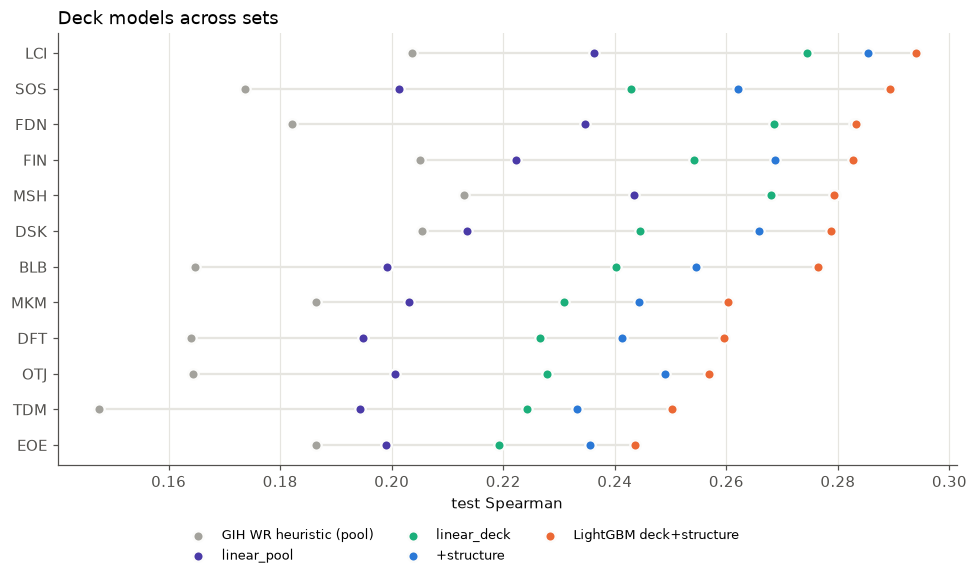

set,GIH WR heuristic (pool),linear_pool,linear_deck,+structure,LightGBM deck+structure,DraftEncoder +deck,test drafts
str,f64,f64,f64,f64,f64,f64,i64
"""LCI""",0.2036,0.2362,0.2744,0.2854,0.294,NaN,19069
"""SOS""",0.1738,0.2013,0.243,0.2621,0.2894,NaN,15299
"""FDN""",0.1821,0.2346,0.2685,0.2828,0.2832,0.2754,18593
"""FIN""",0.2051,0.2223,0.2543,0.2687,0.2827,NaN,19950
"""MSH""",0.213,0.2434,0.2679,0.2796,0.2794,0.2664,9770
"""DSK""",0.2055,0.2135,0.2446,0.2659,0.2788,NaN,23606
"""BLB""",0.1648,0.1992,0.2402,0.2546,0.2764,0.2516,21756
"""MKM""",0.1863,0.2031,0.231,0.2444,0.2604,NaN,22159
"""DFT""",0.1641,0.1948,0.2266,0.2413,0.2597,NaN,19791


mean over sets: {'GIH WR heuristic (pool)': 0.183, 'linear_pool': 0.2119, 'linear_deck': 0.2435, '+structure': 0.2585, 'LightGBM deck+structure': 0.2712}


In [17]:
series = [("pool_top23:gih_wr", "GIH WR heuristic (pool)", GRAY, "results.json"),
          ("linear_pool", "linear_pool", VIOLET, "results.json"),
          ("linear_deck", "linear_deck", AQUA, "results.json"),
          ("+structure", "+structure", BLUE, "improve_deck.json"),
          ("lgbm_deck+structure", "LightGBM deck+structure", ORANGE, "improve_deck.json")]
sets = sorted(p.parent.parent.name.split(".")[0] for p in ROOT.glob("results/*.PremierDraft/draftencoder/improve_deck.json"))
data = {s: {**json.loads((ROOT / "results" / f"{s}.PremierDraft" / "draftencoder" / "results.json").read_text()),
            **json.loads((ROOT / "results" / f"{s}.PremierDraft" / "draftencoder" / "improve_deck.json").read_text())}
        for s in sets}
order = sorted(sets, key=lambda s: data[s]["lgbm_deck+structure"]["spearman"])
fig, ax = plt.subplots(figsize=(9, 5.4))
for k, lab, c, _ in series:
    ax.scatter([data[s][k]["spearman"] for s in order], range(len(order)), color=c, s=46, label=lab,
               edgecolor=SURFACE, lw=1.5, zorder=3)
for i, s in enumerate(order):
    xs = [data[s][k]["spearman"] for k, *_ in series]
    ax.plot([min(xs), max(xs)], [i, i], color=GRID, lw=1.5, zorder=1)
ax.set_yticks(range(len(order)), order); ax.grid(axis="y", visible=False)
ax.set_xlabel("test Spearman")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.12), ncol=3, fontsize=8.5)
ax.set_title("Deck models across sets", loc="left")
plt.tight_layout(); plt.show()

cross = pl.DataFrame([{"set": s, **{lab: round(data[s][k]["spearman"], 4) for k, lab, *_ in series},
                       "DraftEncoder +deck": round(data[s].get("draftencoder_big+deck", data[s].get("draftencoder_paper+deck", {})).get("spearman", np.nan), 4),
                       "test drafts": data[s]["linear_deck"]["n"]} for s in order[::-1]])
display(cross)
mean = {lab: float(np.mean([data[s][k]["spearman"] for s in sets])) for k, lab, *_ in series}
print("mean over sets:", {k: round(v, 4) for k, v in mean.items()})

## 9. Takeaways

1. **The registered deck is the best input.** On every one of the 12 sets, `linear_deck` beats `linear_pool` by
   about 0.03 Spearman: which 23 cards and which lands the drafter chose carries real information. The pick
   sequence adds nothing on top of it.
2. **The best model is simple.** Deck counts + rank + a few structure features (colours, splash, creatures), fitted as
   a binomial logistic regression or LightGBM, scores 0.24-0.29 Spearman across sets. LightGBM leads on average
   (0.271 vs 0.259) and ties on MSH, where an average of the two is best (0.285).
3. **That is close to the ceiling for the spread these models predict.** Bo1 runs of at most 9 games are noisy, so
   even a perfect model, at the spread these models predict (sd about 6 points), would score only about 0.26-0.28. Further progress has
   to come from finding bigger real differences between decks.
4. **The transformer doesn't pay off here.** DraftEncoder without oracle-text card features never beats the linear
   pool model, and with the deck it lands just under `linear_deck`, after 20-60 minutes of training instead of seconds.
   Card text, which this reimplementation doesn't have, is probably where the paper's gain comes from.
5. **Card value ≈ a single number per card.** Pair synergy is about 50× smaller than card power and does not improve
   held-out games. Learned weights track public GIH WR closely (Spearman 0.81). They are still worth fitting:
   on the same final pool, the GIH WR heuristic averages 0.18 across sets, against 0.21 for learned weights.
6. **Two traps:** win rates from cards *cast* look great per game (AUC 0.84) but score decks badly, because winners
   cast more. And rank lowers p at a fixed deck because it sets the opponents, so never read it as skill.